In [1]:
# ============================================================
# ORGANIC AVOCADO PRICE PREDICTION
# AND DEC 2020 -> DEC 2021 FORECAST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)



In [2]:


# LOAD DATA

dataset = pd.read_csv("avocado-updated-2020.csv")

dataset["date"] = pd.to_datetime(dataset["date"], errors="coerce")

print("Original shape:", dataset.shape)
print(dataset.head())

print("\nColumns:")
print(dataset.columns.tolist())



Original shape: (33045, 13)
        date  average_price  total_volume       4046       4225      4770  \
0 2015-01-04           1.22      40873.28    2819.50   28287.42     49.90   
1 2015-01-04           1.79       1373.95      57.42     153.88      0.00   
2 2015-01-04           1.00     435021.49  364302.39   23821.16     82.15   
3 2015-01-04           1.76       3846.69    1500.15     938.35      0.00   
4 2015-01-04           1.08     788025.06   53987.31  552906.04  39995.03   

   total_bags  small_bags  large_bags  xlarge_bags          type  year  \
0     9716.46     9186.93      529.53          0.0  conventional  2015   
1     1162.65     1162.65        0.00          0.0       organic  2015   
2    46815.79    16707.15    30108.64          0.0  conventional  2015   
3     1408.19     1071.35      336.84          0.0       organic  2015   
4   141136.68   137146.07     3990.61          0.0  conventional  2015   

              geography  
0                Albany  
1           

In [3]:

#    San Francisco
SF_organic = dataset[(dataset["geography"] == "San Francisco")    &    (dataset["type"] == "organic")].copy()
SF_organic = (SF_organic.sort_values("date").reset_index(drop=True))
print("\norganic San Francisco data:")
print(SF_organic.shape)
print(    SF_organic[["date","average_price","total_volume"]].head())



organic San Francisco data:
(306, 13)
        date  average_price  total_volume
0 2015-01-04           1.18      22630.58
1 2015-01-11           1.12      29676.78
2 2015-01-18           1.27      41482.48
3 2015-01-25           1.34      27146.81
4 2015-02-01           1.06      57802.02


In [4]:

# CHECK MISSING VALUES
print("\nMissing values BEFORE weekly reindexing:")
print(SF_organic[["average_price","total_volume"]].isna().sum())


Missing values BEFORE weekly reindexing:
average_price    0
total_volume     0
dtype: int64


In [5]:
#
SF_organic = SF_organic.set_index("date")
weekly_index = pd.date_range(start=SF_organic.index.min(), end=SF_organic.index.max(), freq="W-SUN")
SF_organic_weekly = (SF_organic.reindex(weekly_index))
SF_organic_weekly.index.name = "date"
print("\nNumber of weekly observations:", len(SF_organic_weekly))


Number of weekly observations: 309


In [6]:
# INTERPOLATE MISSING VALUES
SF_organic_weekly["average_price_interp"] = (SF_organic_weekly["average_price"].interpolate(method="time"))
SF_organic_weekly["total_volume_interp"] = (SF_organic_weekly["total_volume"].interpolate(method="time"))
# Boundary protection
SF_organic_weekly["average_price_interp"] = (SF_organic_weekly["average_price_interp"].ffill().bfill())
SF_organic_weekly["total_volume_interp"] = (SF_organic_weekly["total_volume_interp"].ffill().bfill())
SF_organic_weekly["type"] = "organic"
SF_organic_weekly["geography"] = "San Francisco"
print("\nMissing values AFTER interpolation:")
print(SF_organic_weekly[["average_price_interp", "total_volume_interp"]].isna().sum())




Missing values AFTER interpolation:
average_price_interp    0
total_volume_interp     0
dtype: int64


In [7]:

# RESET INDEX
SF_organic_weekly = (SF_organic_weekly.reset_index())
SF_organic_weekly["year"] = (SF_organic_weekly["date"].dt.year)


In [8]:
# SEASONAL FEATURES
SF_organic_weekly["week_of_year"] = (SF_organic_weekly["date"].dt.isocalendar().week.astype(int))
SF_organic_weekly["sin_year"] = np.sin( 2 * np.pi * SF_organic_weekly["week_of_year"] / 52.0)
SF_organic_weekly["cos_year"] = np.cos( 2 * np.pi * SF_organic_weekly["week_of_year"] / 52.0)

In [9]:
# PRICE LAGS
SF_organic_weekly["price_1week"] = (SF_organic_weekly[ "average_price_interp"].shift(1))
SF_organic_weekly["price_2week"] = (SF_organic_weekly["average_price_interp"].shift(2))
SF_organic_weekly["price_4week"] = (SF_organic_weekly["average_price_interp"].shift(4))

In [10]:

# 9. VOLUME LAGS
SF_organic_weekly["volume_1week"] = (SF_organic_weekly["total_volume_interp"].shift(1))
SF_organic_weekly["volume_2week"] = (SF_organic_weekly["total_volume_interp"].shift(2))
SF_organic_weekly["volume_4week"] = (SF_organic_weekly["total_volume_interp"].shift(4))

In [11]:
# OPTIONAL PRICE CHANGE FEATURES
SF_organic_weekly["price_change_1_2week"] = (SF_organic_weekly["price_1week"] - SF_organic_weekly["price_2week"])
SF_organic_weekly["price_change_1_4week"] = (SF_organic_weekly["price_1week"] - SF_organic_weekly["price_4week"])


Final modeling data shape:
(305, 26)

Model period:
2015-02-01 00:00:00 to 2020-11-29 00:00:00


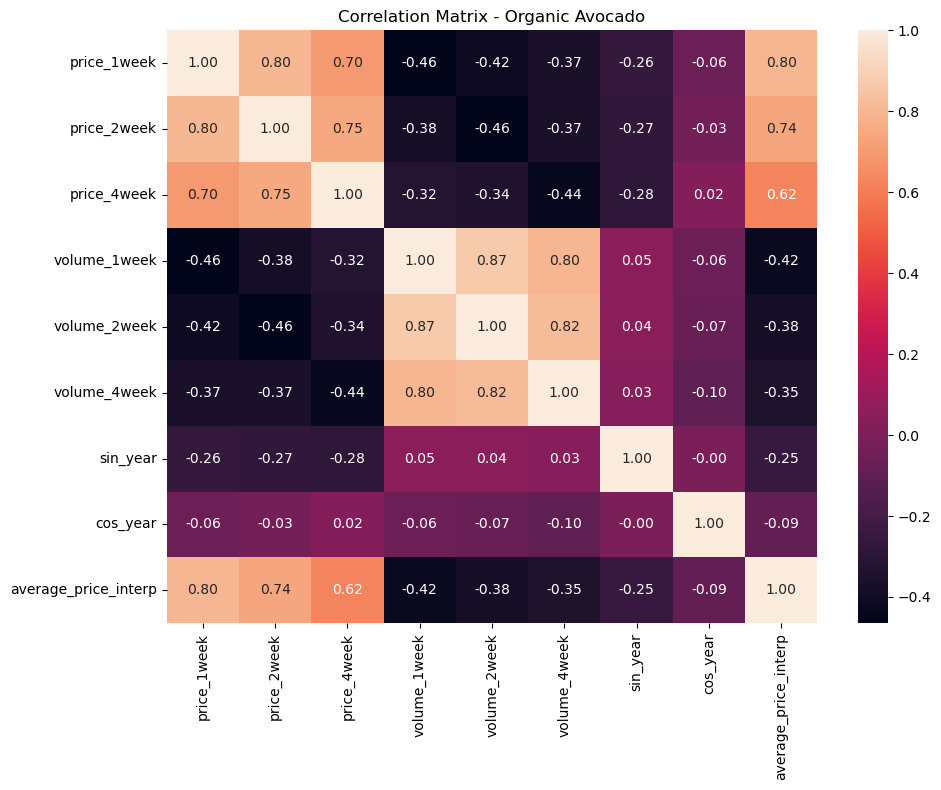

In [12]:
# FEATURE SETS
features_A = ["price_1week", "price_2week", "price_4week"]
features_B = ["price_1week", "price_2week", "price_4week",    "volume_1week",    "volume_2week",    "volume_4week"]
features_C = [    "price_1week",    "price_2week",    "price_4week",    "volume_1week",    "volume_2week",    "volume_4week",    "sin_year",    "cos_year"]
target = "average_price_interp"

# PREPARE MODELING DATA
model_data = SF_organic_weekly.dropna(subset=features_C + [target]).copy()
model_data = (model_data.sort_values("date").reset_index(drop=True))
print("\nFinal modeling data shape:")
print(model_data.shape)
print("\nModel period:")
print(model_data["date"].min(), "to", model_data["date"].max())
#+CORRELATION MATRIX
correlation_columns = (features_C + [target])
plt.figure(figsize=(10, 8))
sns.heatmap(model_data[correlation_columns].corr(), annot=True, fmt=".2f")
plt.title("Correlation Matrix - Organic Avocado")
plt.tight_layout()
plt.show()



In [13]:

# EXPANDING YEAR CROSS VALIDATION
years = sorted(model_data["year"].unique())
year_splits = []
for test_year in years[1:]:

    train_idx = model_data.index[model_data["year"] < test_year].to_numpy()
    test_idx = model_data.index[model_data["year"] == test_year].to_numpy()
    if (
        len(train_idx) == 0
        or len(test_idx) == 0
    ):
        continue
    year_splits.append((train_idx, test_idx))
print("\nYEAR-BASED CROSS VALIDATION:")
for i, (train_idx, test_idx) in enumerate( year_splits,    start=1):
    train_years = ( model_data        .loc[train_idx, "year"].unique())
    test_year = (model_data.loc[test_idx, "year"].unique())

    print(f"Fold {i}: "f"Train = {train_years} "f"--> Test = {test_year}"    )


YEAR-BASED CROSS VALIDATION:
Fold 1: Train = [2015] --> Test = [2016]
Fold 2: Train = [2015 2016] --> Test = [2017]
Fold 3: Train = [2015 2016 2017] --> Test = [2018]
Fold 4: Train = [2015 2016 2017 2018] --> Test = [2019]
Fold 5: Train = [2015 2016 2017 2018 2019] --> Test = [2020]


In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

In [15]:
# MODELS
models = {"Linear Regression": LinearRegression(), "KNN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=5))]), "SVR": Pipeline([("scaler", StandardScaler()),
            ("model", SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma=0.01))]),    "Random Forest": RandomForestRegressor(n_estimators=500, max_depth=5, min_samples_leaf=1, min_samples_split=2, random_state=42, n_jobs=-1)}

In [16]:
from sklearn.model_selection import GridSearchCV

knn_grid = {"model__n_neighbors": [3, 5, 7, 9, 11],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]}

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

grid_knn = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

X = model_data[features_C]
y = model_data[target]

grid_knn.fit(X, y)
best_knn = grid_knn.best_estimator_
print("Best KNN parameters:")
print(grid_knn.best_params_)

print("Best KNN CV MAE:")
print(-grid_knn.best_score_)

Best KNN parameters:
{'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'uniform'}
Best KNN CV MAE:
0.21756593406593408


In [17]:
print("Features used:")
print(features_C)

print("\nTarget:")
print(target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features used:
['price_1week', 'price_2week', 'price_4week', 'volume_1week', 'volume_2week', 'volume_4week', 'sin_year', 'cos_year']

Target:
average_price_interp

X shape: (305, 8)
y shape: (305,)


In [18]:
svr_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__epsilon": [0.01, 0.05, 0.1, 0.2],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(kernel="rbf"))
])

grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_svr.fit(X, y)
best_svr = grid_svr.best_estimator_
print(grid_svr.best_params_)
print(-grid_svr.best_score_)

{'model__C': 1, 'model__epsilon': 0.05, 'model__gamma': 0.01}
0.17459252617190973


In [19]:
rf_grid = {
    "n_estimators": [50, 100, 300, 500],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_grid,
    cv=year_splits,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_rf.fit(X, y)
best_rf = grid_rf.best_estimator_
print(grid_rf.best_params_)
print(-grid_rf.best_score_)

{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}
0.18383485272361436


In [20]:
models_tuned = {
    "Linear Regression": LinearRegression(),
    "KNN tuned": best_knn,
    "SVR tuned": best_svr,
    "Random Forest tuned": best_rf
}

In [21]:

# 1EVALUATION FUNCTIONS
def evaluate_model(model_name,    feature_set_name,    test_year,    y_true,    y_pred):

    return {"Feature_Set": feature_set_name, "Model": model_name, "Test_Year": test_year, 
        "MAE": mean_absolute_error( y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE":root_mean_squared_error(y_true, y_pred),
        "R2":r2_score( y_true, y_pred)}

In [22]:
# CROSS VALIDATION FUNCTION
def year_cross_validation(data, features, feature_set_name, model, model_name):

    results = []
    for fold, (train_idx, test_idx) in enumerate( year_splits, start=1):
        X_train = data.loc[train_idx, features]
        X_test = data.loc[test_idx,features]
        y_train = data.loc[train_idx, target]
        y_test = data.loc[test_idx, target]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        test_year = (data.loc[test_idx, "year"].iloc[0])
        result = evaluate_model(model_name, feature_set_name, test_year, y_test, y_pred)
        result["Fold"] = fold
        results.append(result)
    return pd.DataFrame(results)

In [23]:
#####´´FEATURE SETS
feature_sets = {"A: Price only": features_A, "B: Price + Volume": features_B, "C: Price + Volume + Seasonality": features_C}

In [24]:
#RUN CROSS VALIDATION#
all_results = []
for feature_set_name, features in feature_sets.items():
    for model_name, model in models.items():
        result = year_cross_validation(
            data=model_data,

            features=features,

            feature_set_name=feature_set_name,

            model=model,

            model_name=model_name
        )
        all_results.append(result)

all_results = pd.concat(all_results, ignore_index=True)
# SUMMARY
summary = (all_results.groupby(["Feature_Set", "Model"])[["MAE","MSE","RMSE","R2"]].mean().reset_index().sort_values("MAE"))
print("\nAVERAGE CROSS-VALIDATION PERFORMANCE")
print(summary.to_string(index=False))



AVERAGE CROSS-VALIDATION PERFORMANCE
                    Feature_Set             Model      MAE      MSE     RMSE        R2
                  A: Price only Linear Regression 0.139518 0.050969 0.215547  0.380919
                  A: Price only               SVR 0.142075 0.050081 0.213373  0.401004
              B: Price + Volume Linear Regression 0.149852 0.053201 0.223366  0.287377
              B: Price + Volume               SVR 0.154093 0.051545 0.219522  0.330641
C: Price + Volume + Seasonality               SVR 0.176024 0.061105 0.236331  0.240084
C: Price + Volume + Seasonality Linear Regression 0.188679 0.068893 0.249645  0.146942
                  A: Price only               KNN 0.194817 0.071561 0.259907  0.042880
              B: Price + Volume               KNN 0.199311 0.077213 0.264449  0.066558
                  A: Price only     Random Forest 0.200655 0.080608 0.268585  0.058854
C: Price + Volume + Seasonality     Random Forest 0.202523 0.079413 0.269069  0.055188
     

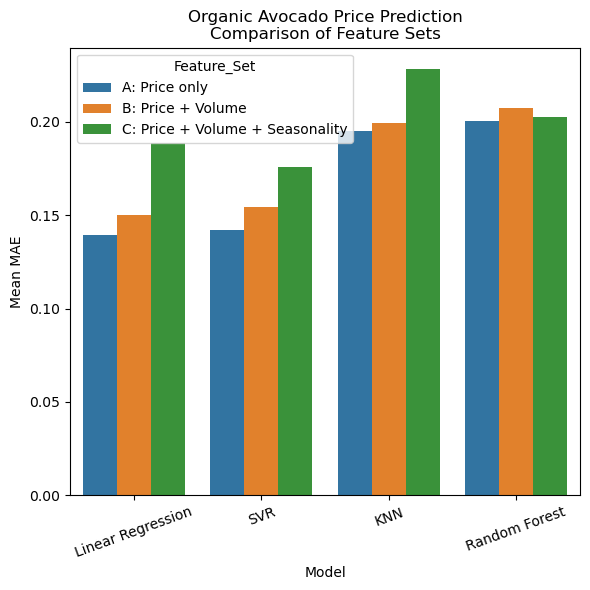

In [25]:
# MODEL COMPARISON PLOT
plt.figure(figsize=(6, 6))
sns.barplot(data=summary, x="Model",    y="MAE",    hue="Feature_Set")
plt.ylabel("Mean MAE")
plt.xlabel("Model")
plt.title("Organic Avocado Price Prediction\n"    "Comparison of Feature Sets")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


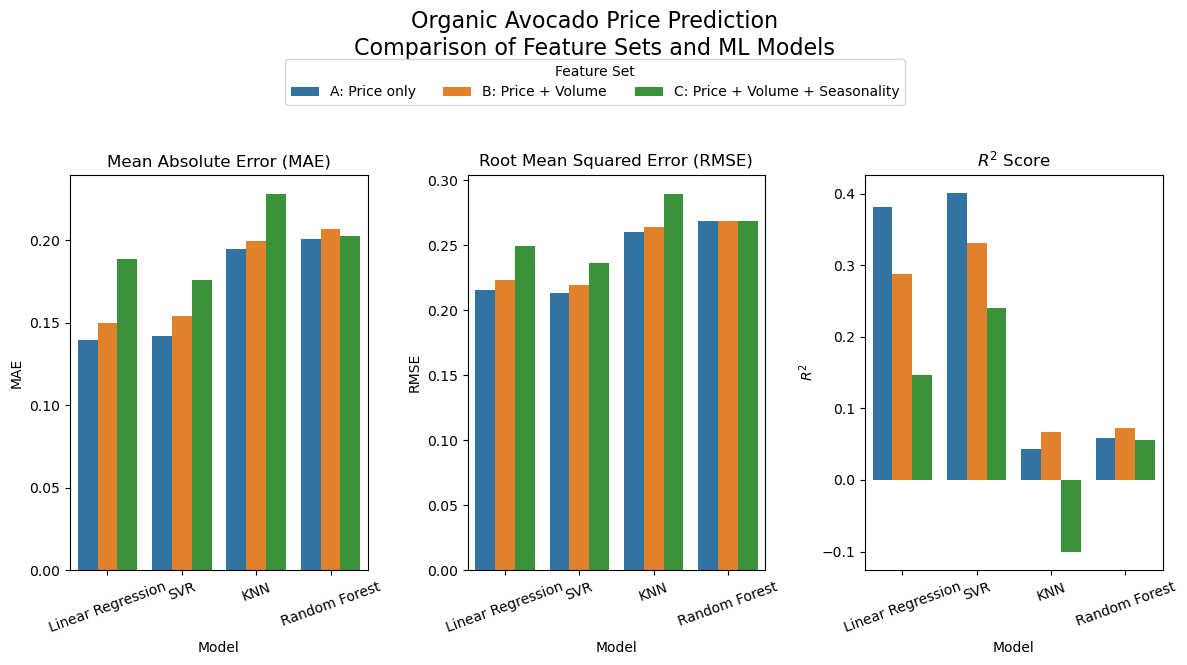

In [26]:

# MODEL COMPARISON: MAE, RMSE AND R2 TOGETHER
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
sns.barplot(data=summary, x="Model", y="MAE", hue="Feature_Set", ax=axes[0])
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=summary, x="Model", y="RMSE", hue="Feature_Set", ax=axes[1])
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=20)
sns.barplot(data=summary, x="Model", y="R2", hue="Feature_Set", ax=axes[2])
axes[2].set_title(r"$R^2$ Score")
axes[2].set_xlabel("Model")
axes[2].set_ylabel(r"$R^2$")
axes[2].tick_params(axis="x", rotation=20)
axes[0].get_legend().remove()
axes[1].get_legend().remove()
axes[2].get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Feature Set", loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=3)
fig.suptitle("Organic Avocado Price Prediction\n" "Comparison of Feature Sets and ML Models", fontsize=16, y=1.10)
plt.tight_layout()
plt.savefig("Organic_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

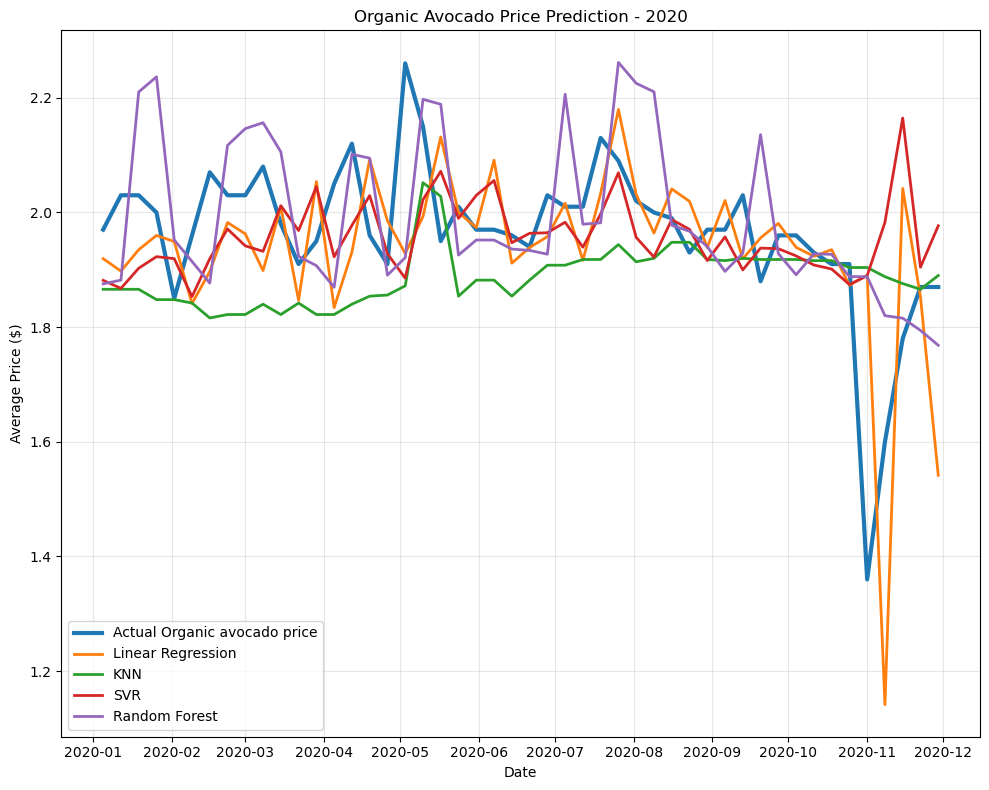

In [27]:
# TEST YEAR 2020
train_2020 = model_data[model_data["year"] < 2020].copy()
test_2020 = model_data[model_data["year"] == 2020].copy()
X_train_2020 = train_2020[features_C]
X_test_2020 = test_2020[features_C]
y_train_2020 = train_2020[target]
y_test_2020 = test_2020[target]
#TEST ALL FOUR METHODS ON 2020
predictions_2020 = {}
for model_name, model in models.items():
    model.fit(X_train_2020, y_train_2020)
    predictions_2020[model_name] = model.predict(X_test_2020)
# 24. 2020 ACTUAL VS DIFFERENT METHODS
plt.figure(figsize=(10, 8))
plt.plot(test_2020["date"],y_test_2020, linewidth=3, label="Actual Organic avocado price")
for model_name, pred in predictions_2020.items():
    plt.plot(test_2020["date"], pred, linewidth=2, label=model_name)
plt.xlabel("Date")
plt.ylabel("Average Price ($)")
plt.title("Organic Avocado Price Prediction - 2020")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Organic_avocado_prediction_2020_all_methods.png", dpi=300, bbox_inches="tight")
plt.show()



In [28]:
# METRICS FOR EACH METHOD IN 2020
results_2020 = []
for model_name, pred in predictions_2020.items():
    results_2020.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test_2020, pred),
        "RMSE": root_mean_squared_error(y_test_2020, pred),
        "R2": r2_score(y_test_2020, pred)})
results_2020 = pd.DataFrame(results_2020)
print(    "\n2020 MODEL PERFORMANCE:")
print(    results_2020.sort_values("MAE").to_string(index=False))


2020 MODEL PERFORMANCE:
            Model      MAE     RMSE        R2
              SVR 0.099260 0.145877 -0.208558
Linear Regression 0.108162 0.155910 -0.380508
    Random Forest 0.109708 0.149284 -0.265656
              KNN 0.123583 0.161546 -0.482115


In [29]:


# FUTURE FORECAST:
# DECEMBER 2020 -> DECEMBER 2021## 26. FORECAST DATES# 
forecast_start = pd.Timestamp("2020-12-06")
forecast_end = pd.Timestamp("2021-12-26")
future_dates = pd.date_range(start=forecast_start,    end=forecast_end,    freq="W-SUN")
print(    "\nForecast period:",    future_dates.min(),    "to",    future_dates.max())
#ONLY USE DATA BEFORE FORECAST START
historical_data = SF_organic_weekly[SF_organic_weekly["date"]    < forecast_start].copy()
historical_data = (    historical_data    .sort_values("date").reset_index(drop=True))
price_features = features_C
price_train = historical_data.dropna(subset=price_features + ["average_price_interp"]).copy()
X_price_train = price_train[price_features]
y_price_train = price_train["average_price_interp"]
# FUTURE VOLUME MODEL# Volume itself must also be forecast because future volume# is unknown.# 
volume_features = ["volume_1week",    "volume_2week",    "volume_4week",    "sin_year",    "cos_year"]
volume_train = historical_data.dropna(subset=volume_features + ["total_volume_interp"]).copy()
X_volume_train = volume_train[volume_features]
y_volume_train = volume_train["total_volume_interp"]
volume_model = RandomForestRegressor(n_estimators=500, random_state=42, n_jobs=-1)
volume_model.fit(X_volume_train, y_volume_train)
# RECURSIVE VOLUME FORECAST
volume_history = list(historical_data["total_volume_interp"].values)
future_volume = []
for date in future_dates:
    week = date.isocalendar().week
    sin_year = np.sin(2 * np.pi * week / 52.0)
    cos_year = np.cos(2 * np.pi * week / 52.0)
    volume_1week = volume_history[-1]
    volume_2week = volume_history[-2]
    volume_4week = volume_history[-4]
    X_future_volume = pd.DataFrame([[volume_1week, volume_2week, volume_4week, sin_year, cos_year]], columns=volume_features)
    predicted_volume = volume_model.predict(X_future_volume)[0]
    predicted_volume = max(predicted_volume, 0)
    future_volume.append(predicted_volume)
    volume_history.append(predicted_volume)
# RECURSIVE PRICE FORECAST FUNCTION# 
def recursive_price_forecast(model,    historical_data,    future_dates,    future_volume):
    trained_model = clone(model)
    trained_model.fit(X_price_train, y_price_train    )
    price_history = list(historical_data["average_price_interp"].values)
    volume_history = list(historical_data["total_volume_interp"].values)
    predictions = []
    for i, date in enumerate(future_dates):
        week = date.isocalendar().week
        sin_year = np.sin(2 * np.pi * week / 52.0)
        cos_year = np.cos(2 * np.pi * week / 52.0)
        # PRICE LAGS
        price_1week = price_history[-1]
        price_2week = price_history[-2]
        price_4week = price_history[-4]
        # VOLUME LAGS
        volume_1week = volume_history[-1]
        volume_2week = volume_history[-2]
        volume_4week = volume_history[-4]
        X_future = pd.DataFrame([[price_1week, price_2week, price_4week, volume_1week, volume_2week, volume_4week, sin_year, cos_year]], columns=price_features)
        predicted_price = (trained_model.predict(X_future)[0])
        predictions.append(predicted_price)
        # Recursive update
        price_history.append(predicted_price)
        volume_history.append(future_volume[i])
    return np.array(predictions)



Forecast period: 2020-12-06 00:00:00 to 2021-12-26 00:00:00


In [30]:
## FORECAST WITH ALL METHODS#++++
future_predictions = {}
for model_name, model in models.items():
    print(f"Forecasting with {model_name}...")
    future_predictions[model_name] = recursive_price_forecast(
        model=model,
        historical_data=
            historical_data,
        future_dates=
            future_dates,
        future_volume=
            future_volume
    )


Forecasting with Linear Regression...
Forecasting with KNN...
Forecasting with SVR...
Forecasting with Random Forest...


In [31]:

# FUTURE DATAFRAME# 
forecast_df = pd.DataFrame({
    "date":
        future_dates
})
for model_name in future_predictions:
    forecast_df[
        model_name
    ] = future_predictions[
        model_name
    ]


forecast_df[
    "Predicted Volume"
] = future_volume


print(
    "\nFuture Organic avocado forecast:"
)

print(
    forecast_df.head(10)
)




Future Organic avocado forecast:
        date  Linear Regression    KNN       SVR  Random Forest  \
0 2020-12-06           1.837374  1.804  1.849831       1.870493   
1 2020-12-13           1.846449  1.890  1.836831       1.895217   
2 2020-12-20           1.844329  1.932  1.831910       1.900369   
3 2020-12-27           1.845825  1.960  1.826886       1.879130   
4 2021-01-03           1.844640  1.960  1.822266       1.899586   
5 2021-01-10           1.836945  1.988  1.813718       1.900270   
6 2021-01-17           1.840455  1.976  1.812219       1.900527   
7 2021-01-24           1.835680  1.976  1.807221       1.900695   
8 2021-01-31           1.830725  1.974  1.804940       1.901552   
9 2021-02-07           1.821685  1.982  1.802209       1.900444   

   Predicted Volume  
0       59865.36916  
1       59152.51394  
2       58086.15080  
3       56700.79636  
4       57937.00144  
5       56871.78416  
6       57356.21738  
7       58487.40070  
8       61648.30560  
9       

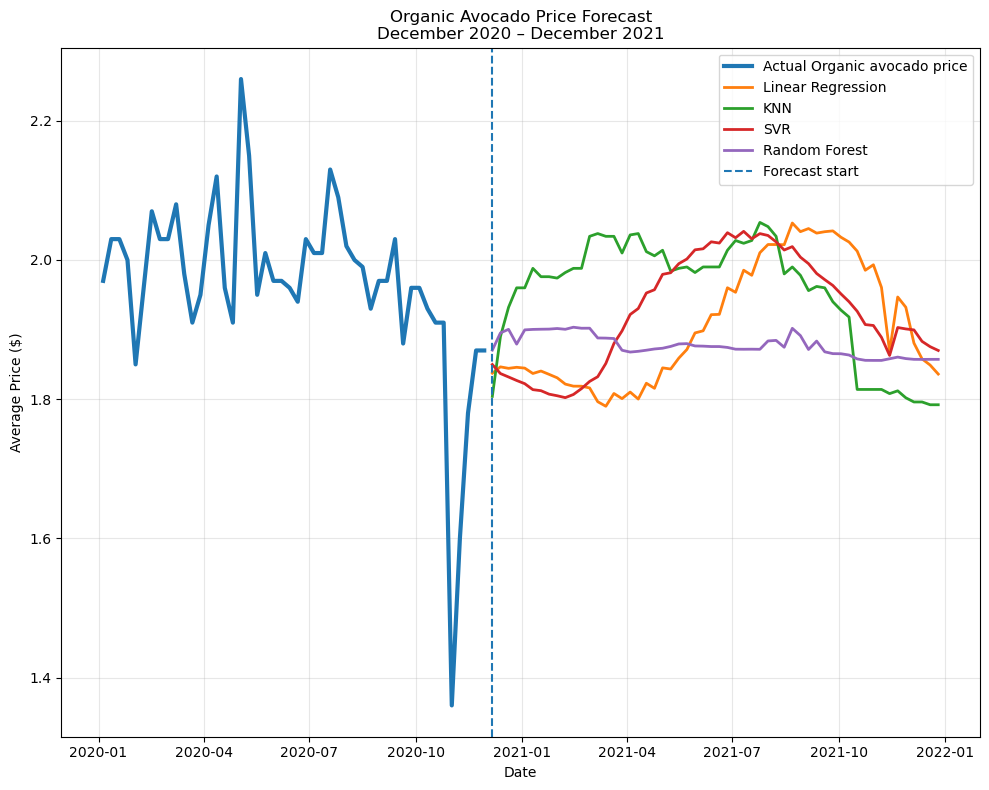

In [32]:
# HISTORICAL + FUTURE FORECAST

plt.figure(figsize=(10, 8))
plot_history = historical_data[
    historical_data["date"]
    >= pd.Timestamp("2020-01-01")
]
plt.plot(plot_history["date"], plot_history["average_price_interp"], linewidth=3, label="Actual Organic avocado price")
for model_name in models.keys():
    plt.plot(forecast_df["date"],forecast_df[model_name], linewidth=2, label=model_name)
plt.axvline(forecast_start,linestyle="--", linewidth=1.5, label="Forecast start")
plt.xlabel("Date")
plt.ylabel("Average Price ($)")
plt.title("Organic Avocado Price Forecast\n" "December 2020 – December 2021")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Organic_avocado_forecast_2021_all_models.png", dpi=300, bbox_inches="tight")
plt.show()


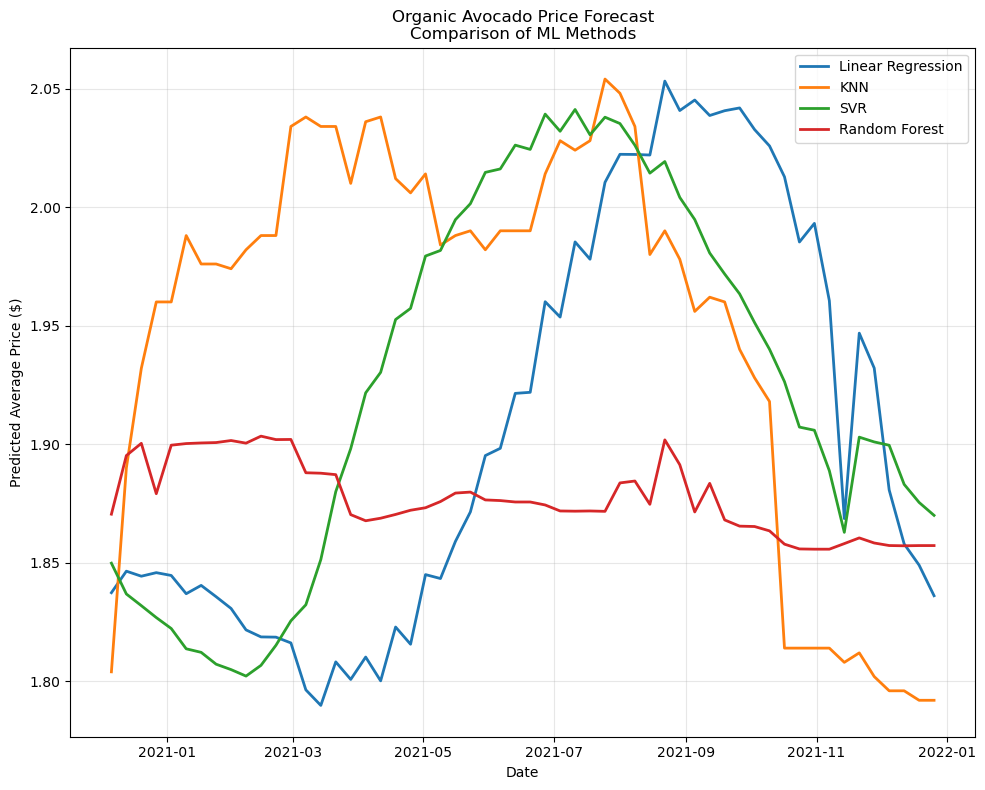

In [33]:
 
# FORECAST-ONLY COMPARISON
# 
plt.figure(figsize=(10, 8))
for model_name in models.keys():
    plt.plot(forecast_df["date"], forecast_df[model_name],linewidth=2, label=model_name)
plt.xlabel("Date")
plt.ylabel("Predicted Average Price ($)")
plt.title("Organic Avocado Price Forecast\n" "Comparison of ML Methods")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Organic_avocado_2021_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


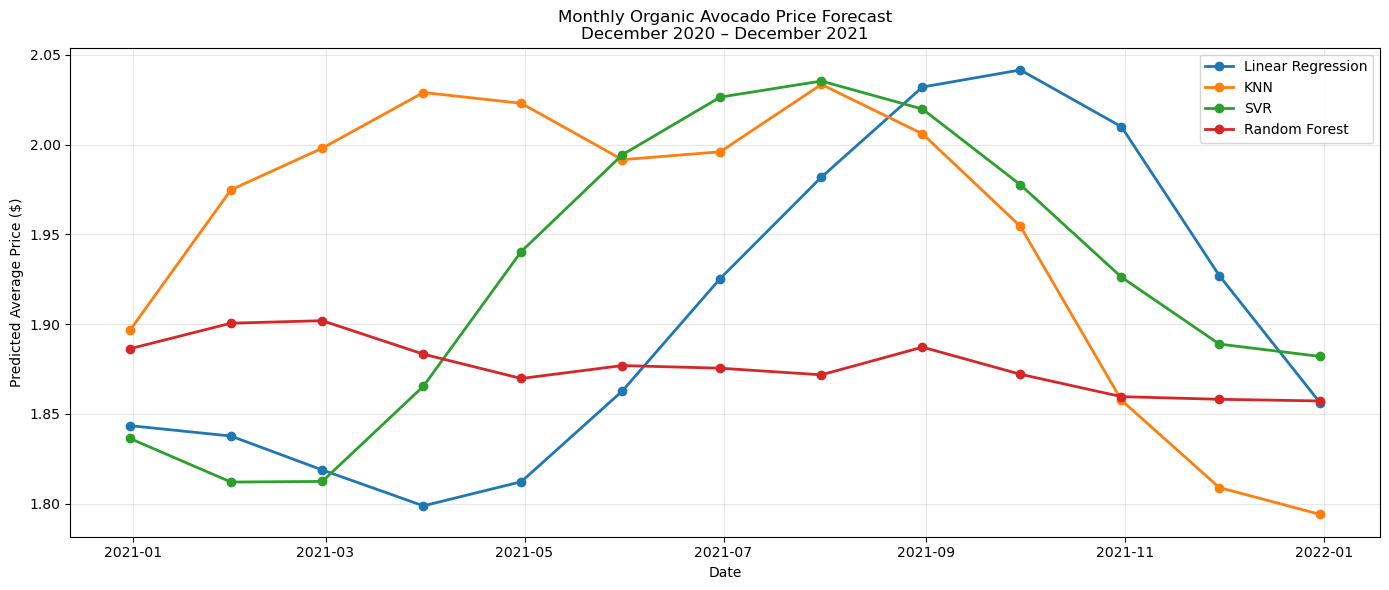

In [34]:
# MONTHLY FORECAST
forecast_monthly = (forecast_df.set_index("date") [list(models.keys())]
    .resample("ME")
    .mean()
    .reset_index()
)
plt.figure(figsize=(14, 6))
for model_name in models.keys():
    plt.plot(forecast_monthly["date"], forecast_monthly[model_name], marker="o", linewidth=2, label=model_name)
plt.xlabel("Date")
plt.ylabel("Predicted Average Price ($)")
plt.title("Monthly Organic Avocado Price Forecast\n" "December 2020 – December 2021")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig("Organic_avocado_2021_monthly_forecast.png", dpi=300, bbox_inches="tight")
#plt.show()